# **Tugas Akhir**   
### Analisis Perbandingan Model Deep Learning untuk Klasifikasi Emosi pada Teks Opini Publik Berbahasa Indonesia

2372023 - Eben Praus Yosia



---



# Part 8a: RoBERTa - Skema 1 "Embeddings" (dilatih dari nol)
Tokenisasi level kata + vocabulary dari train -> embedding acak -> encoder RoBERTa 12 layer (acak) -> kepala klasifikasi -> softmax. Seluruh model dilatih dari nol

Keterangan: pada skema ini RoBERTa tidak memakai tokenizer BPE aslinya dan tidak memuat bobot pre-trained. Ini perlakuan yang disengaja, yang serupa dengan IndoBERT (Part 07a). Hanya ukuran arsitektur yang diambil dari config `flax-community/indonesian-roberta-base`. Performa diperkirakan rendah, dan hal ini wajar

Aturan: satu run, tanpa grid search; evaluasi hanya di validation; test set tidak disentuh.

- Input : `data/train.csv`, `data/val.csv`, `data/label_map.json` (+ `data/vocab_nn.json` opsional untuk pengecekan)
- Output: `outputs/roberta_embeddings_val_results.json`, `outputs/models/roberta_embeddings.pt`, grafik di `outputs/figures/`

### Step 1 - Konfigurasi, seed, dan load data

In [1]:
import os, json, re, random, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from transformers import AutoConfig, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.utils.data import DataLoader
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

DATA_DIR = "data"
FIG_DIR = "outputs/figures"
MODEL_DIR = "outputs/models"
RESULT_PATH = "outputs/roberta_embeddings_val_results.json"

TEXT_COL, LABEL_COL = "text", "label"
SEED = 42

# Arsitektur: ukuran diambil dari config checkpoint (flax-community/indonesian-roberta-base), bobot tidak dimuat sama sekali
MODEL_NAME = "flax-community/indonesian-roberta-base"

# Tokenisasi level kata, sama dengan Part 04b, Part 05a, Part 06a
TOKEN_PATTERN = r"\w+|[^\w\s]"
MIN_FREQ = 2
MAX_LEN = 64 # jumlah kata maksimum (belum termasuk token khusus awal/akhir)
MAX_POS = MAX_LEN + 6 # panjang tabel posisi: cukup untuk token khusus & offset posisi RoBERTa

# Token khusus (konvensi RoBERTa)
SPECIALS = ["<s>", "<pad>", "</s>", "<unk>"]
PAD_TOK, UNK_TOK, CLS_TOK, SEP_TOK = "<pad>", "<unk>", "<s>", "</s>" # <s> = awal, </s> = akhir

# Hyperparameter tetap (tanpa tuning)
# Dilatih dari nol -> lr lebih besar daripada fine-tuning (2e-5 terlalu kecil
# untuk bobot acak). Satu nilai standar dipakai, tidak dicari.
BATCH_SIZE = 32
EPOCHS = 15
LR = 1e-4
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
CLIP_NORM = 1.0


for d in (FIG_DIR, MODEL_DIR): os.makedirs(d, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df   = pd.read_csv(f"{DATA_DIR}/val.csv")

with open(f"{DATA_DIR}/label_map.json") as f:
    label_map = json.load(f)
labels = list(label_map.keys()) # urutan: anger, fear, joy, love, neutral, sad
NUM_CLASSES = len(labels)
assert all(label_map[l] == i for i, l in enumerate(labels))
y_train_list = [label_map[l] for l in train_df[LABEL_COL]]
y_val_list = [label_map[l] for l in val_df[LABEL_COL]]
print("Train:", train_df.shape, "| Val:", val_df.shape, "| Kelas:", labels)

Train: (4921, 2) | Val: (1055, 2) | Kelas: ['anger', 'fear', 'joy', 'love', 'neutral', 'sad']


### Step 2 - Tokenisasi level kata & vocabulary (hanya dari train)
Skema 1 "Embeddings" - Hal yg disengaja (bukan bug):  
Pada skema ini, RoBERTa tidak memakai tokenizer subword aslinya sama sekali (`AutoTokenizer` tidak diimpor). Tokenisasi diganti dengan tokenisasi level kata (regex yang sama dengan baseline/TextCNN/BiLSTM) dan vocabulary kata dari data train. Embedding layer diinisialisasi acak menurut vocabulary kata ini, dan
seluruh model (embedding + encoder) dilatih dari nol, tanpa bobot pre-trained apa pun. Tujuannya supaya mekanisme "embeddings" konsisten di semua model + baseline

In [2]:
TOKEN_RE = re.compile(TOKEN_PATTERN)
def tokenize(text):
    return TOKEN_RE.findall(text)

train_tokens = [tokenize(t) for t in train_df[TEXT_COL]]
val_tokens = [tokenize(t) for t in val_df[TEXT_COL]]

# Vocabulary level kata: hanya dari train
# Token khusus mengikuti konvensi RoBERTa (urutan menentukan id)
counter = Counter(tok for t in train_tokens for tok in t)
words = sorted(w for w, c in counter.items() if c >= MIN_FREQ)
itos = SPECIALS + words
stoi = {w: i for i, w in enumerate(itos)}
PAD_ID, UNK_ID, CLS_ID, SEP_ID = stoi[PAD_TOK], stoi[UNK_TOK], stoi[CLS_TOK], stoi[SEP_TOK]
VOCAB_SIZE = len(itos)

# Bukti: kata di vocabulary ini identik dengan vocabulary TextCNN/BiLSTM (vocab_nn.json dari Part 05a + Part 06a), jika ada
vp = f"{DATA_DIR}/vocab_nn.json"
if os.path.exists(vp):
    with open(vp, encoding="utf-8") as f: nn_itos = json.load(f)["itos"]
    print("Kata identik dengan vocab_nn.json (TextCNN/BiLSTM):", set(nn_itos[2:]) == set(words))

def encode_words(tokens):
    ids = [stoi.get(t, UNK_ID) for t in tokens][:MAX_LEN] # potong kata jika > MAX_LEN
    return [CLS_ID] + ids + [SEP_ID] # tambah token awal & akhir

train_ids = [encode_words(t) for t in train_tokens]
val_ids = [encode_words(t) for t in val_tokens]

len_tok = np.array([len(t) for t in train_tokens])
tok_val_flat = [t for ts in val_tokens for t in ts]
cakupan_val = np.mean([t in stoi for t in tok_val_flat])
trunc_pct = (len_tok > MAX_LEN).mean() * 100
print(f"Ukuran vocabulary kata (termasuk {len(SPECIALS)} token khusus): {VOCAB_SIZE}")
print(f"Panjang token train: rata-rata {len_tok.mean():.1f} | persentil 95 = {np.percentile(len_tok, 95):.0f} | maks = {len_tok.max()}")
print(f"Teks train yang terpotong oleh MAX_LEN={MAX_LEN}: {trunc_pct:.2f}%")
print(f"Cakupan token validation oleh vocabulary: {cakupan_val*100:.2f}%")
print("Contoh ->", train_tokens[0][:8], "->", train_ids[0][:10])
PAD_FOR_COLLATE = PAD_ID

Kata identik dengan vocab_nn.json (TextCNN/BiLSTM): True
Ukuran vocabulary kata (termasuk 4 token khusus): 5718
Panjang token train: rata-rata 19.5 | persentil 95 = 51 | maks = 82
Teks train yang terpotong oleh MAX_LEN=64: 0.14%
Cakupan token validation oleh vocabulary: 85.55%
Contoh -> ['365', '.', 'kalau', 'mau', 'gestun', 'limit', 'kamu', 'di'] -> [0, 59, 16, 2340, 3104, 3, 2896, 2359, 1205, 3]


In [3]:
def make_collate(pad_id):
    def collate(batch): # batch: list of (ids, label); pad ke panjang terpanjang di batch
        L = max(len(ids) for ids, _ in batch)
        input_ids = torch.full((len(batch), L), pad_id, dtype=torch.long)
        attn = torch.zeros((len(batch), L), dtype=torch.long)
        for i, (ids, _) in enumerate(batch):
            input_ids[i, :len(ids)] = torch.tensor(ids)
            attn[i, :len(ids)] = 1
        return {"input_ids": input_ids, "attention_mask": attn,
                "labels": torch.tensor([y for _, y in batch], dtype=torch.long)}
    return collate

collate_fn = make_collate(PAD_FOR_COLLATE)
train_loader = DataLoader(list(zip(train_ids, y_train_list)), batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collate_fn, generator=torch.Generator().manual_seed(SEED))
val_loader   = DataLoader(list(zip(val_ids, y_val_list)), batch_size=64, shuffle=False, collate_fn=collate_fn)
b0 = next(iter(val_loader))
print("Contoh batch -> input_ids:", tuple(b0["input_ids"].shape), "| attention_mask:", tuple(b0["attention_mask"].shape))

Contoh batch -> input_ids: (64, 59) | attention_mask: (64, 59)


### Step 3 - Model RoBERTa dari nol (dari config, tanpa bobot pre-trained)
Ukuran arsitektur (jumlah layer, hidden size) mengikuti config checkpoint `flax-community/indonesian-roberta-base`, tetapi tidak ada bobot yang dimuat, dan semua parameter diinisialisasi acak

In [4]:
# Model dibuat dari config saja (from_config) -> bobot acak. Tidak ada from_pretrained untuk bobot
config = AutoConfig.from_pretrained(MODEL_NAME) # hanya config.json (jumlah layer, hidden size, dst), bukan bobot
config.vocab_size = VOCAB_SIZE # embedding mengikuti vocabulary kata, bukan vocabulary subword
config.num_labels = NUM_CLASSES
config.max_position_embeddings = MAX_POS
config.pad_token_id = PAD_ID
config.bos_token_id, config.eos_token_id = CLS_ID, SEP_ID # RoBERTa: <s> dan </s>

model = AutoModelForSequenceClassification.from_config(config).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

emb = model.get_input_embeddings().weight
print(f"Arsitektur: {config.model_type} | layer: {config.num_hidden_layers} | hidden: {config.hidden_size} | head: {config.num_attention_heads}")
print(f"Vocabulary embedding model: {emb.shape[0]} (= vocabulary kata dari train, bukan vocabulary subword asli)")
print(f"Embedding acak: std = {emb.std().item():.4f} (initializer_range = {config.initializer_range})")
print(f"Total parameter dilatih: {n_params/1e6:.1f} juta | semua requires_grad: {all(p.requires_grad for p in model.parameters())}")

config.json:   0%|          | 0.00/671 [00:00<?, ?B/s]

Arsitektur: roberta | layer: 12 | hidden: 768 | head: 12
Vocabulary embedding model: 5718 (= vocabulary kata dari train, bukan vocabulary subword asli)
Embedding acak: std = 0.0200 (initializer_range = 0.02)
Total parameter dilatih: 90.1 juta | semua requires_grad: True


### Step 4 - Training (satu run, 15 epoch, model epoch terakhir yang dievaluasi)
Loss `CrossEntropyLoss` (tanpa class weight)  
Optimizer AdamW  
Warmup 10% lalu penurunan linear, gradient clipping 1.0, mixed precision di GPU  
Tidak memilih epoch terbaik di validation  
Akan ditunjukkan lewat grafik jika seandainya terjadi overfitting

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
use_amp = device.type == "cuda" # mixed precision (fp16) di GPU: lebih cepat & hemat memori
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def run_epoch(loader, train):
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for batch in loader:
            ids = batch["input_ids"].to(device); am = batch["attention_mask"].to(device); yb = batch["labels"].to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(input_ids=ids, attention_mask=am).logits
            loss = criterion(logits.float(), yb)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
                scaler.step(optimizer); scaler.update(); scheduler.step()
            tot_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return tot_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)
    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)): history[k].append(v)
    print(f"Epoch {ep:2d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f} | {time.time()-t0:.0f} dtk")
print(f"Selesai dalam {time.time()-t0:.0f} detik")

torch.save(model.state_dict(), f"{MODEL_DIR}/roberta_embeddings.pt") # ukuran file bisa ratusan MB

Epoch  1/15 | train loss 1.5797 acc 0.3497 | val loss 1.2350 acc 0.5526 | 19 dtk
Epoch  2/15 | train loss 1.0999 acc 0.6196 | val loss 1.0148 acc 0.6616 | 36 dtk
Epoch  3/15 | train loss 0.8583 acc 0.7127 | val loss 0.9107 acc 0.6995 | 53 dtk
Epoch  4/15 | train loss 0.6731 acc 0.7842 | val loss 1.0335 acc 0.6929 | 75 dtk
Epoch  5/15 | train loss 0.4992 acc 0.8476 | val loss 0.9585 acc 0.7090 | 92 dtk
Epoch  6/15 | train loss 0.3502 acc 0.9012 | val loss 1.0691 acc 0.7090 | 110 dtk
Epoch  7/15 | train loss 0.2820 acc 0.9226 | val loss 1.3357 acc 0.6768 | 127 dtk
Epoch  8/15 | train loss 0.2044 acc 0.9457 | val loss 1.4077 acc 0.6853 | 145 dtk
Epoch  9/15 | train loss 0.1631 acc 0.9575 | val loss 1.5892 acc 0.6853 | 163 dtk
Epoch 10/15 | train loss 0.1360 acc 0.9673 | val loss 1.7537 acc 0.6664 | 180 dtk
Epoch 11/15 | train loss 0.0847 acc 0.9815 | val loss 1.8584 acc 0.6844 | 198 dtk
Epoch 12/15 | train loss 0.0599 acc 0.9882 | val loss 1.8765 acc 0.6863 | 216 dtk
Epoch 13/15 | train l

### Step 5 - Kurva training vs validation (loss & accuracy)

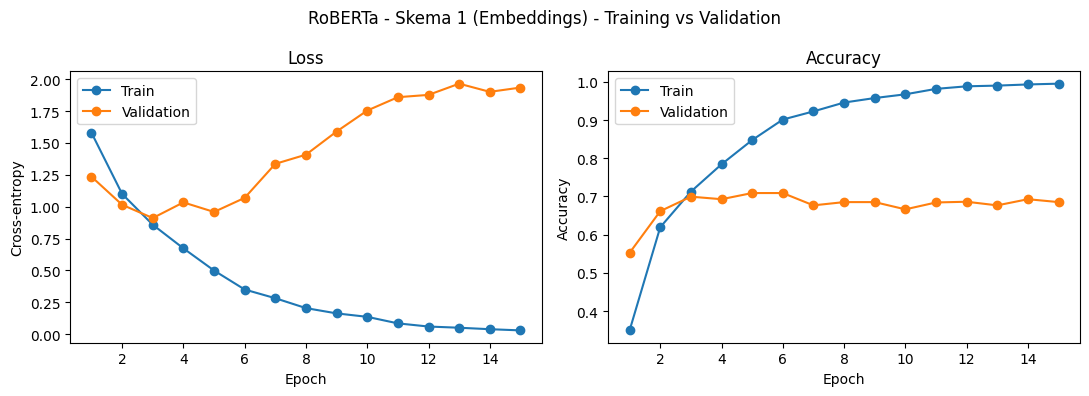

Val loss terendah di epoch 3 (0.9107); epoch terakhir: 1.9338


In [6]:
ep_axis = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ep_axis, history["train_loss"], "o-", label="Train")
axes[0].plot(ep_axis, history["val_loss"], "o-", label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy"); axes[0].legend()
axes[1].plot(ep_axis, history["train_acc"], "o-", label="Train")
axes[1].plot(ep_axis, history["val_acc"], "o-", label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
fig.suptitle("RoBERTa - Skema 1 (Embeddings) - Training vs Validation")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/08a_roberta_embeddings_curves.png", dpi=150)
plt.show()

best_ep = int(np.argmin(history["val_loss"])) + 1
print(f"Val loss terendah di epoch {best_ep} ({min(history['val_loss']):.4f}); epoch terakhir: {history['val_loss'][-1]:.4f}")

### Step 6 - Evaluasi di validation set (model epoch terakhir)

In [7]:
model.eval()
preds = []
with torch.no_grad():
    for batch in val_loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(input_ids=batch["input_ids"].to(device), attention_mask=batch["attention_mask"].to(device)).logits
        preds.append(logits.argmax(1).cpu())
pred_idx = torch.cat(preds).numpy()

y_val_str = val_df[LABEL_COL].values
y_pred_str = np.array([labels[i] for i in pred_idx])

acc = accuracy_score(y_val_str, y_pred_str)
macro_p = precision_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_r = recall_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_f1 = f1_score(y_val_str, y_pred_str, average="macro")

kelas_terbanyak = train_df[LABEL_COL].value_counts().idxmax()
acc_mayoritas = (val_df[LABEL_COL] == kelas_terbanyak).mean()
print(f"Acuan 'tebak selalu {kelas_terbanyak}': accuracy = {acc_mayoritas:.4f}")
print(f"RoBERTa - Skema 1 (Embeddings) (val): accuracy = {acc:.4f} | macro-F1 = {macro_f1:.4f}")
print("Jumlah kelas yang pernah diprediksi:", len(set(y_pred_str)), "dari", NUM_CLASSES)

# Satu tabel: per kelas + accuracy + macro avg + weighted avg
rapor = classification_report(y_val_str, y_pred_str, labels=labels, output_dict=True, zero_division=0)
rapor_df = pd.DataFrame(rapor).T.drop(index="accuracy")
rapor_df.loc["accuracy"] = [np.nan, np.nan, acc, len(y_val_str)]
rapor_df = rapor_df.loc[labels + ["accuracy", "macro avg", "weighted avg"]]
rapor_df["support"] = rapor_df["support"].astype(int)
rapor_df.round(4).fillna("")

Acuan 'tebak selalu neutral': accuracy = 0.2825
RoBERTa - Skema 1 (Embeddings) (val): accuracy = 0.6853 | macro-F1 = 0.6932
Jumlah kelas yang pernah diprediksi: 6 dari 6


,precision,recall,f1-score,support
anger,0.6772,0.6369,0.6564,168
fear,0.7338,0.75,0.7418,136
joy,0.7485,0.6614,0.7022,189
love,0.5906,0.7788,0.6718,113
neutral,0.637,0.6477,0.6423,298
sad,0.777,0.7152,0.7448,151
accuracy,,,0.6853,1055
macro avg,0.694,0.6983,0.6932,1055
weighted avg,0.6909,0.6853,0.6859,1055


### Step 7 - Confusion matrix (validation)

,pred_anger,pred_fear,pred_joy,pred_love,pred_neutral,pred_sad
asli_anger,107,8,4,10,33,6
asli_fear,10,102,3,5,13,3
asli_joy,7,6,125,19,25,7
asli_love,6,2,5,88,11,1
asli_neutral,24,18,27,22,193,14
asli_sad,4,3,3,5,28,108


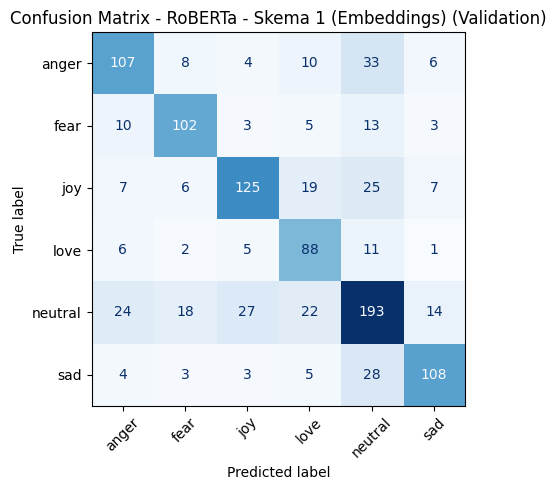

In [8]:
cm = confusion_matrix(y_val_str, y_pred_str, labels=labels)
display(pd.DataFrame(cm, index=[f"asli_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - RoBERTa - Skema 1 (Embeddings) (Validation)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/08a_roberta_embeddings_confusion_matrix_val.png", dpi=150)
plt.show()

### Step 8 - Simpan hasil

In [9]:
# Format JSON seragam (kunci inti sama: model, feature_extraction, split, accuracy, dll)
with open(RESULT_PATH, "w") as f:
    json.dump({"model": "RoBERTa", "feature_extraction": "embeddings", "split": "validation",
               "accuracy": round(float(acc), 4), "macro_precision": round(float(macro_p), 4),
               "macro_recall": round(float(macro_r), 4), "macro_f1": round(float(macro_f1), 4),
               "extractor": "tokenizer kata + embedding acak, arsitektur RoBERTa dari config flax-community/indonesian-roberta-base, dilatih dari nol (tanpa bobot pretrained)",
               "vocab_size": int(VOCAB_SIZE), "max_len": int(MAX_LEN), "epochs": EPOCHS, "lr": LR,
               "batch_size": BATCH_SIZE, "n_trainable_params": int(n_params), "evaluated_epoch": "last"}, f, indent=2)
print("Tersimpan:", RESULT_PATH)

Tersimpan: outputs/roberta_embeddings_val_results.json


### Notes Part 8a:
- Vocabulary | MAX_LEN | parameter dilatih: 5718 | 64 | 90.1 juta
- Teks train terpotong oleh MAX_LEN: 0.14%
- Train acc | Val acc (epoch terakhir): 0.9951 | 0.6853
- Val loss terendah di epoch: epoch ke-3 (epoch terakhir: 15)
- Accuracy | Macro-F1 (validation): 0.6853 | 0.6932 (acuan tebak-mayoritas: 0.2825)
- Macro-Precision | Macro-Recall: 0.6940 | 0.6983
- F1 tertinggi | terendah per kelas: sad (0.7448) | neutral (0.6423)
- Pasangan kelas yang paling sering tertukar: anger dan neutral (57 kesalahan di dua arah)
- Test set belum disentuh.